In [1]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('toyota.csv')

In [3]:
print(df.head())

   model  year  price transmission  mileage fuelType  tax   mpg  engineSize
0   GT86  2016  16000       Manual    24089   Petrol  265  36.2         2.0
1   GT86  2017  15995       Manual    18615   Petrol  145  36.2         2.0
2   GT86  2015  13998       Manual    27469   Petrol  265  36.2         2.0
3   GT86  2017  18998       Manual    14736   Petrol  150  36.2         2.0
4   GT86  2017  17498       Manual    36284   Petrol  145  36.2         2.0


In [4]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6738 entries, 0 to 6737
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         6738 non-null   object 
 1   year          6738 non-null   int64  
 2   price         6738 non-null   int64  
 3   transmission  6738 non-null   object 
 4   mileage       6738 non-null   int64  
 5   fuelType      6738 non-null   object 
 6   tax           6738 non-null   int64  
 7   mpg           6738 non-null   float64
 8   engineSize    6738 non-null   float64
dtypes: float64(2), int64(4), object(3)
memory usage: 473.9+ KB
None


In [5]:
print(df.describe())

              year         price        mileage          tax          mpg  \
count  6738.000000   6738.000000    6738.000000  6738.000000  6738.000000   
mean   2016.748145  12522.391066   22857.413921    94.697240    63.042223   
std       2.204062   6345.017587   19125.464147    73.880776    15.836710   
min    1998.000000    850.000000       2.000000     0.000000     2.800000   
25%    2016.000000   8290.000000    9446.000000     0.000000    55.400000   
50%    2017.000000  10795.000000   18513.000000   135.000000    62.800000   
75%    2018.000000  14995.000000   31063.750000   145.000000    69.000000   
max    2020.000000  59995.000000  174419.000000   565.000000   235.000000   

        engineSize  
count  6738.000000  
mean      1.471297  
std       0.436159  
min       0.000000  
25%       1.000000  
50%       1.500000  
75%       1.800000  
max       4.500000  


In [6]:
numeric_columns = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\nЧисловые признаки ({len(numeric_columns)}):")
for col in numeric_columns:
    print(f"  - {col}")


Числовые признаки (6):
  - year
  - price
  - mileage
  - tax
  - mpg
  - engineSize


In [7]:
print("\nПропущенные значения:")
print(df[numeric_columns].isnull().sum())


Пропущенные значения:
year          0
price         0
mileage       0
tax           0
mpg           0
engineSize    0
dtype: int64


In [8]:
df_clean = df[numeric_columns].dropna()

In [9]:
target_column = 'price'
feature_columns = [col for col in numeric_columns if col != target_column]

X = df_clean[feature_columns]
y = df_clean[target_column]

In [10]:
print(f"\nПризнаки для модели ({len(feature_columns)}):")
for col in feature_columns:
    print(f"  - {col}")
print(f"\nЦелевая переменная: {target_column}")
print(f"Количество образцов: {len(X)}")


Признаки для модели (5):
  - year
  - mileage
  - tax
  - mpg
  - engineSize

Целевая переменная: price
Количество образцов: 6738


### МОДЕЛЬ 1: ВСЕ ЧИСЛОВЫЕ ПРИЗНАКИ

In [11]:
model1 = LinearRegression()
model1.fit(X, y)


y_pred1 = model1.predict(X)

r2_model1 = r2_score(y, y_pred1)


print("\nФормула регрессии (Модель 1):")
print(f"Price = {model1.intercept_:.2f}", end="")
for i, col in enumerate(feature_columns):
    sign = "+" if model1.coef_[i] >= 0 else ""
    print(f" {sign} {model1.coef_[i]:.2f} * {col}", end="")
print()

print(f"\nКоэффициенты модели:")
print(f"Свободный член (intercept): {model1.intercept_:.2f}")
for i, col in enumerate(feature_columns):
    print(f"  {col}: {model1.coef_[i]:.6f}")



Формула регрессии (Модель 1):
Price = -1688456.90 + 835.29 * year  -0.08 * mileage  -1.42 * tax + 21.76 * mpg + 11529.34 * engineSize

Коэффициенты модели:
Свободный член (intercept): -1688456.90
  year: 835.294404
  mileage: -0.078737
  tax: -1.418482
  mpg: 21.760205
  engineSize: 11529.336293


In [12]:
print(f"\nКоэффициент детерминации R²: {r2_model1:.4f}")
print(f"\nИнтерпретация:")
print(f"Модель объясняет {r2_model1*100:.2f}% дисперсии цены автомобиля.")
if r2_model1 > 0.8:
    print("Это указывает на очень хорошее качество модели.")
elif r2_model1 > 0.6:
    print("Это указывает на хорошее качество модели.")
elif r2_model1 > 0.4:
    print("Это указывает на умеренное качество модели.")
else:
    print("Это указывает на низкое качество модели.")


Коэффициент детерминации R²: 0.7638

Интерпретация:
Модель объясняет 76.38% дисперсии цены автомобиля.
Это указывает на хорошее качество модели.


### ПРОГНОЗ ЦЕНЫ ДЛЯ НОВОГО АВТОМОБИЛЯ (Модель 1)

### Создание примера для прогноза (используем средние значения)

In [13]:
example_values = {}
print("\nЗначения признаков для прогноза:")
for col in feature_columns:
    example_values[col] = X[col].mean()
    print(f"  {col}: {example_values[col]:.2f}")

X_example = pd.DataFrame([example_values])
price_prediction1 = model1.predict(X_example)[0]
print(f"\nПрогнозируемая цена автомобиля: {price_prediction1:.2f}")



Значения признаков для прогноза:
  year: 2016.75
  mileage: 22857.41
  tax: 94.70
  mpg: 63.04
  engineSize: 1.47

Прогнозируемая цена автомобиля: 12522.39


### ДОПОЛНИТЕЛЬНОЕ ЗАДАНИЕ - МОДЕЛЬ 2

###  Вычисление корреляционной матрицы

In [14]:
correlation_matrix = df_clean[numeric_columns].corr()

print("\nКорреляционная матрица признаков с ценой:")
price_correlations = correlation_matrix[target_column].drop(target_column).sort_values(ascending=False)
print(price_correlations)


Корреляционная матрица признаков с ценой:
engineSize    0.727592
year          0.420959
tax           0.214498
mpg          -0.039910
mileage      -0.297936
Name: price, dtype: float64


###  Найти два признака, наиболее сильно коррелирующие между собой

In [15]:
max_corr = 0
feature_to_remove = None
corr_pair = None

for i, col1 in enumerate(feature_columns):
    for col2 in feature_columns[i+1:]:
        corr_value = abs(correlation_matrix.loc[col1, col2])
        if corr_value > max_corr:
            max_corr = corr_value
            corr_col1_price = abs(correlation_matrix.loc[col1, target_column])
            corr_col2_price = abs(correlation_matrix.loc[col2, target_column])
            
            if corr_col1_price < corr_col2_price:
                feature_to_remove = col1
                corr_pair = (col1, col2)
            else:
                feature_to_remove = col2
                corr_pair = (col1, col2)

In [16]:
print(f"\nНаиболее коррелирующие признаки между собой:")
print(f"  {corr_pair[0]} и {corr_pair[1]}")
print(f"  Корреляция между ними: {max_corr:.4f}")
print(f"\nКорреляция с ценой:")
print(f"  {corr_pair[0]} - Price: {abs(correlation_matrix.loc[corr_pair[0], target_column]):.4f}")
print(f"  {corr_pair[1]} - Price: {abs(correlation_matrix.loc[corr_pair[1], target_column]):.4f}")
print(f"\nИсключаемый признак: {feature_to_remove}")



Наиболее коррелирующие признаки между собой:
  year и mileage
  Корреляция между ними: 0.7277

Корреляция с ценой:
  year - Price: 0.4210
  mileage - Price: 0.2979

Исключаемый признак: mileage


### Построение Модели 2

In [17]:
feature_columns_model2 = [col for col in feature_columns if col != feature_to_remove]
X_model2 = df_clean[feature_columns_model2]

model2 = LinearRegression()
model2.fit(X_model2, y)


,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [18]:
y_pred2 = model2.predict(X_model2)

r2_model2 = r2_score(y, y_pred2)


In [19]:
print("\nФормула регрессии (Модель 2):")
print(f"Price = {model2.intercept_:.2f}", end="")
for i, col in enumerate(feature_columns_model2):
    sign = "+" if model2.coef_[i] >= 0 else ""
    print(f" {sign} {model2.coef_[i]:.2f} * {col}", end="")
print()


Формула регрессии (Модель 2):
Price = -2678094.40 + 1325.63 * year  -1.27 * tax + 17.62 * mpg + 10991.72 * engineSize


In [20]:
print(f"\nКоэффициенты модели:")
print(f"Свободный член (intercept): {model2.intercept_:.2f}")
for i, col in enumerate(feature_columns_model2):
    print(f"  {col}: {model2.coef_[i]:.6f}")


Коэффициенты модели:
Свободный член (intercept): -2678094.40
  year: 1325.626232
  tax: -1.268544
  mpg: 17.616724
  engineSize: 10991.716704


In [21]:
print(f"\nКоэффициент детерминации R²: {r2_model2:.4f}")
print(f"Модель объясняет {r2_model2*100:.2f}% дисперсии цены автомобиля.")


Коэффициент детерминации R²: 0.7387
Модель объясняет 73.87% дисперсии цены автомобиля.


### ПРОГНОЗ ЦЕНЫ ДЛЯ НОВОГО АВТОМОБИЛЯ (Модель 2)

In [22]:
example_values_model2 = {col: example_values[col] for col in feature_columns_model2}
print("\nЗначения признаков для прогноза:")
for col in feature_columns_model2:
    print(f"  {col}: {example_values_model2[col]:.2f}")


Значения признаков для прогноза:
  year: 2016.75
  tax: 94.70
  mpg: 63.04
  engineSize: 1.47


In [23]:
X_example_model2 = pd.DataFrame([example_values_model2])
price_prediction2 = model2.predict(X_example_model2)[0]
print(f"\nПрогнозируемая цена автомобиля: {price_prediction2:.2f}")


Прогнозируемая цена автомобиля: 12522.39


### СРАВНЕНИЕ МОДЕЛЕЙ

In [24]:
print(f"\nМодель 1 (все {len(feature_columns)} признаков):")
print(f"  R² = {r2_model1:.4f}")
print(f"  Прогноз для примера: {price_prediction1:.2f}")



Модель 1 (все 5 признаков):
  R² = 0.7638
  Прогноз для примера: 12522.39


In [25]:
print(f"\nМодель 2 ({len(feature_columns_model2)} признаков, исключен '{feature_to_remove}'):")
print(f"  R² = {r2_model2:.4f}")
print(f"  Прогноз для примера: {price_prediction2:.2f}")


Модель 2 (4 признаков, исключен 'mileage'):
  R² = 0.7387
  Прогноз для примера: 12522.39


In [26]:
print(f"\nРазница в R²: {abs(r2_model1 - r2_model2):.4f}")


Разница в R²: 0.0251


In [27]:
if r2_model1 > r2_model2:
    print(f"\nВывод: Модель 1 прогнозирует цену лучше на {(r2_model1 - r2_model2)*100:.2f}%.")
    print("Включение всех признаков дает более точную модель.")
elif r2_model2 > r2_model1:
    print(f"\nВывод: Модель 2 прогнозирует цену лучше на {(r2_model2 - r2_model1)*100:.2f}%.")
    print("Исключение коррелирующего признака улучшило модель.")
else:
    print("\nВывод: Обе модели показывают одинаковое качество прогнозирования.")



Вывод: Модель 1 прогнозирует цену лучше на 2.51%.
Включение всех признаков дает более точную модель.


# Визуализация результатов

# График для Модели 1

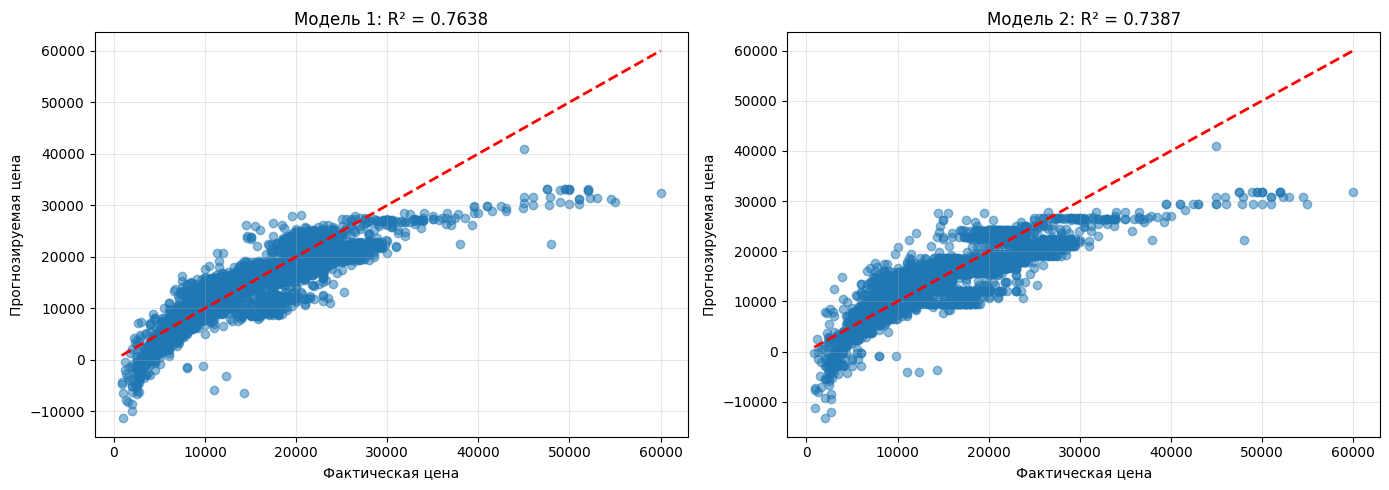

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График для Модели 1
axes[0].scatter(y, y_pred1, alpha=0.5)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axes[0].set_xlabel('Фактическая цена')
axes[0].set_ylabel('Прогнозируемая цена')
axes[0].set_title(f'Модель 1: R² = {r2_model1:.4f}')
axes[0].grid(True, alpha=0.3)

# График для Модели 2
axes[1].scatter(y, y_pred2, alpha=0.5)
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2)
axes[1].set_xlabel('Фактическая цена')
axes[1].set_ylabel('Прогнозируемая цена')
axes[1].set_title(f'Модель 2: R² = {r2_model2:.4f}')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

> Графики сохранены в файл 'model_comparison.png'
> 
> ЛАБОРАТОРНАЯ РАБОТА ЗАВЕРШЕНА